In [12]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [13]:
d = 14
alpha = 0.05
languages = ["C", "C++", "Java", "Python"]

In [14]:
O = np.array([
    20 + d,
    25 + (d % 10),
    30 + (d % 7),
    35 + (d % 5)
])

In [15]:
N = O.sum()
E = np.full(len(O), N / len(O))

In [16]:
contrib = (O - E) ** 2 / E
chi_sq = contrib.sum()

In [17]:
df = len(O) - 1


In [18]:
critical_value = stats.chi2.ppf(1 - alpha, df)
p_value = 1 - stats.chi2.cdf(chi_sq, df)

In [19]:
print("1. Last two digits of Student ID: d =", d)

table = pd.DataFrame({
    "Language": languages,
    "Observed (O)": O,
    "Expected (E)": E.round(2),
    "(O-E)": (O - E).round(2),
    "(O-E)^2/E": contrib.round(4)
})
print("\n2 & 5. Observed and Expected Frequencies:")
print(table.to_string(index=False))
print(f"Total N = {N}")

print("\n3. H0: Students have an equal preference for C, C++, Java and Python "
      "(each language has proportion 0.25).")
print("4. H1: Students do NOT have an equal preference for the four languages "
      "(at least one proportion differs from 0.25).")

print(f"\n6. Chi-Square statistic: χ² = {chi_sq:.4f}")
print(f"7. Degrees of freedom: df = k - 1 = {len(O)} - 1 = {df}")
print(f"8. Critical value (α = {alpha}, df = {df}): {critical_value:.4f}")
print(f"   p-value: {p_value:.4f}")

if chi_sq > critical_value:
    decision = "Reject H0"
    conclusion = ("At the 5% significance level, there is sufficient evidence that "
                  "students do NOT have an equal preference for the four programming "
                  "languages.")
else:
    decision = "Fail to reject H0"
    conclusion = ("At the 5% significance level, there is not sufficient evidence to "
                  "say preferences differ; the data are consistent with students "
                  "having an equal preference for C, C++, Java and Python.")

print(f"\n9. Decision: χ² ({chi_sq:.4f}) {'>' if chi_sq > critical_value else '<='} "
      f"critical value ({critical_value:.4f}) and p = {p_value:.4f} "
      f"{'<' if p_value < alpha else '>='} {alpha}  →  {decision}")
print(f"10. Conclusion: {conclusion}")


1. Last two digits of Student ID: d = 14

2 & 5. Observed and Expected Frequencies:
Language  Observed (O)  Expected (E)  (O-E)  (O-E)^2/E
       C            34          33.0    1.0     0.0303
     C++            29          33.0   -4.0     0.4848
    Java            30          33.0   -3.0     0.2727
  Python            39          33.0    6.0     1.0909
Total N = 132

3. H0: Students have an equal preference for C, C++, Java and Python (each language has proportion 0.25).
4. H1: Students do NOT have an equal preference for the four languages (at least one proportion differs from 0.25).

6. Chi-Square statistic: χ² = 1.8788
7. Degrees of freedom: df = k - 1 = 4 - 1 = 3
8. Critical value (α = 0.05, df = 3): 7.8147
   p-value: 0.5979

9. Decision: χ² (1.8788) <= critical value (7.8147) and p = 0.5979 >= 0.05  →  Fail to reject H0
10. Conclusion: At the 5% significance level, there is not sufficient evidence to say preferences differ; the data are consistent with students having an equa

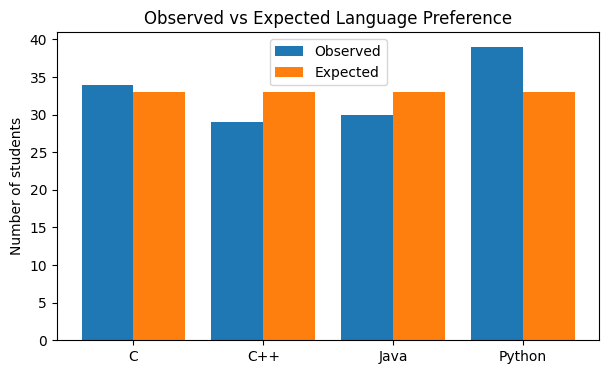

In [20]:
x = np.arange(len(languages))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, O, width=0.4, label="Observed")
plt.bar(x + 0.2, E, width=0.4, label="Expected")
plt.xticks(x, languages)
plt.ylabel("Number of students")
plt.title("Observed vs Expected Language Preference")
plt.legend()
plt.show()


Conclusion: The calculated chi-square value (1.8788) is much smaller than the critical value (7.815), and the p-value (about 0.598) is well above 0.05. So we fail to reject the null hypothesis. In simple terms, the survey results don’t show any real difference in how much students like C, C++, Java or Python. The small differences in the counts are likely just due to chance. At the 5% significance level, we can say students seem to have an equal preference for the four languages.